# Objetivo

O objetivo deste projeto é desenvolver um modelo de Machine Learning capaz de prever a quantidade de kills (`qtKill`) de um jogador em uma partida de CS, utilizando seu histórico de desempenho em partidas anteriores.

In [6]:
# BIBLIOTECAS E IMPORTS

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Localiza a raiz do projeto (a pasta que contém src/) para importar os módulos.
# Funciona abrindo o notebook na raiz do projeto ou dentro de notebooks/.
RAIZ_PROJETO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir())
if str(RAIZ_PROJETO) not in sys.path:
    sys.path.insert(0, str(RAIZ_PROJETO))

# Imports dos módulos do próprio projeto.
from src.data.dataset_final import (
    FEATURE_COLUMNS,
    TARGET_COLUMN,
    carregar_dataset_final,
    separar_entradas_alvo,
)
from src.evaluation.metricas import calcular_metricas
from src.evaluation.resultados import salvar_tabela
from src.models.knn import (
    DISTANCIAS,
    VALORES_K,
    buscar_hiperparametros,
    criar_modelo,
    melhor_configuracao,
    resumo_validacao,
    salvar_resultados,
)
from src.preprocessing.separacao_dados import (
    dividir_por_tempo,
    resumo_separacao,
    verificar_ordem_temporal,
)

print("Quantidade de features oficiais:", len(FEATURE_COLUMNS))

Quantidade de features oficiais: 25


In [7]:
# CARREGAMENTO DO DATASET FINAL

df = carregar_dataset_final()

print(f"Registros: {len(df):,}")
print(f"Colunas: {len(df.columns)}")
display(df.head())
df.info()

Registros: 172,773
Colunas: 29


,idPlayer,idLobbyGame,dtCreatedAt,qtdAnteriores,killsUltimaPartida,nivelAnterior,mediaKills_5,mediaKills_20,mediaKills_hist,mediaDano_5,...,taxaVitorias_20,taxaVitorias_hist,tirosPorKill_5,tirosPorKill_20,tirosPorKill_hist,killsPorRound_5,killsPorRound_20,killsPorRound_hist,desvioKills_20,qtKill
0,2,8,2021-10-12 16:48:09,5,11,2,10.2,10.200000,10.200000,1540.6,...,0.200000,0.200000,27.568627,27.568627,27.568627,0.435897,0.435897,0.435897,3.768289,8
1,2,9,2021-10-17 17:02:08,6,8,2,10.6,9.833333,9.833333,1590.2,...,0.166667,0.166667,28.716981,29.305085,29.305085,0.490741,0.443609,0.443609,3.488075,5
2,2,10,2021-10-17 18:09:18,7,5,2,10.0,9.142857,9.142857,1452.0,...,0.142857,0.142857,26.960000,29.359375,29.359375,0.555556,0.441379,0.441379,3.670993,19
3,2,11,2021-10-17 23:20:21,8,19,2,11.8,10.375000,10.375000,1703.2,...,0.125000,0.125000,23.271186,27.240964,27.240964,0.608247,0.482558,0.482558,4.867898,5
4,2,12,2021-10-18 00:22:34,9,5,1,9.6,9.777778,9.777778,1458.4,...,0.222222,0.222222,25.770833,27.454545,27.454545,0.457143,0.440000,0.440000,4.893306,9


<class 'pandas.DataFrame'>
RangeIndex: 172773 entries, 0 to 172772
Data columns (total 29 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   idPlayer             172773 non-null  int64         
 1   idLobbyGame          172773 non-null  int64         
 2   dtCreatedAt          172773 non-null  datetime64[us]
 3   qtdAnteriores        172773 non-null  int64         
 4   killsUltimaPartida   172773 non-null  int64         
 5   nivelAnterior        172773 non-null  int64         
 6   mediaKills_5         172773 non-null  float64       
 7   mediaKills_20        172773 non-null  float64       
 8   mediaKills_hist      172773 non-null  float64       
 9   mediaDano_5          172773 non-null  float64       
 10  mediaDano_20         172773 non-null  float64       
 11  mediaDano_hist       172773 non-null  float64       
 12  mediaHeadshots_5     172773 non-null  float64       
 13  mediaHeadshots_20    1727

In [8]:
# DEFINIÇÃO DAS ENTRADAS E DO ALVO

# carregar_dataset_final já confere as colunas esperadas e a ausência de nulos.
X, y = separar_entradas_alvo(df)

print("Features utilizadas:")
for coluna in FEATURE_COLUMNS:
    print("-", coluna)

print("\nAlvo:", TARGET_COLUMN)
print("Há valores ausentes nas features?", bool(X.isna().any().any()))
print("Há valores ausentes no alvo?", bool(y.isna().any()))

Features utilizadas:
- qtdAnteriores
- killsUltimaPartida
- nivelAnterior
- mediaKills_5
- mediaKills_20
- mediaKills_hist
- mediaDano_5
- mediaDano_20
- mediaDano_hist
- mediaHeadshots_5
- mediaHeadshots_20
- mediaHeadshots_hist
- mediaRounds_5
- mediaRounds_20
- mediaRounds_hist
- taxaVitorias_5
- taxaVitorias_20
- taxaVitorias_hist
- tirosPorKill_5
- tirosPorKill_20
- tirosPorKill_hist
- killsPorRound_5
- killsPorRound_20
- killsPorRound_hist
- desvioKills_20

Alvo: qtKill
Há valores ausentes nas features? False
Há valores ausentes no alvo? False


In [9]:
# SEPARAÇÃO TEMPORAL

treino, validacao, teste = dividir_por_tempo(df)

# Verifica que as janelas temporais não se sobrepõem.
verificar_ordem_temporal(treino, validacao, teste)

display(resumo_separacao(treino, validacao, teste))

X_treino, y_treino = separar_entradas_alvo(treino)
X_validacao, y_validacao = separar_entradas_alvo(validacao)
X_teste, y_teste = separar_entradas_alvo(teste)

print(f"Treino: {len(X_treino):,} linhas")
print(f"Validação: {len(X_validacao):,} linhas")
print(f"Teste: {len(X_teste):,} linhas")

,Linhas,Porcentagem (%),Primeira data,Última data,Jogadores
Treino,120941,70.0,2021-09-14 19:07:41,2022-01-09 00:05:31,1608
Validação,25916,15.0,2022-01-09 00:06:07,2022-01-26 03:52:44,1549
Teste,25916,15.0,2022-01-26 03:53:43,2022-02-11 13:27:48,1671


Treino: 120,941 linhas
Validação: 25,916 linhas
Teste: 25,916 linhas


# Estratégia

Foi utilizado o algoritmo K-Nearest Neighbors (KNN), que realiza previsões com base nos jogadores com características mais semelhantes.

O conjunto de dados foi dividido temporalmente em treino (70%), validação (15%) e teste (15%), respeitando a ordem cronológica das partidas.

Foram testadas diferentes quantidades de vizinhos (K) e métricas de distância. O melhor modelo foi escolhido com base no menor MAE na validação, sendo utilizado posteriormente no conjunto de teste.

Antes de calcular as distâncias, as features são padronizadas com a média e o desvio do treino. A implementação reutilizável do modelo e da busca está em `src/models/knn.py`, com testes em `tests/test_knn.py`.

In [10]:
# BUSCA DE HIPERPARÂMETROS NA VALIDAÇÃO

print("Valores de K testados:", VALORES_K)
print("Distâncias testadas:", DISTANCIAS)

# Para cada distância, os vizinhos são buscados uma única vez com o maior K e
# reaproveitados para os K menores (ver buscar_hiperparametros em src/models/knn.py).
# A padronização das features usa apenas a média e o desvio do treino.
busca = buscar_hiperparametros(treino, validacao)

# Exibe as 15 melhores combinações, do menor MAE para o maior
display(busca.head(15))

Valores de K testados: [3, 5, 7, 9, 11, 15]
Distâncias testadas: ['euclidean', 'manhattan', 'chebyshev']


,k,distancia,MAE_validacao,RMSE_validacao,R2_validacao
0,15,manhattan,5.548405,7.144417,0.104743
1,15,euclidean,5.568673,7.167370,0.098982
2,15,chebyshev,5.580385,7.179802,0.095853
3,11,manhattan,5.618063,7.225170,0.084391
4,11,euclidean,5.635395,7.244087,0.079590
5,11,chebyshev,5.638044,7.250664,0.077918
6,9,manhattan,5.678568,7.296106,0.066324
7,9,chebyshev,5.699413,7.323697,0.059249
8,9,euclidean,5.702766,7.319193,0.060406
9,7,manhattan,5.766504,7.390904,0.041904


In [11]:
# SELEÇÃO DO MELHOR MODELO

configuracao = melhor_configuracao(busca)
resumo = resumo_validacao(busca, len(validacao))
melhor_mae_validacao = float(resumo.loc[0, "MAE"])

print(f"Melhor K: {configuracao['k']}")
print(f"Melhor distância: {configuracao['distancia']}")
print(f"MAE na validação: {melhor_mae_validacao:.4f}")
display(resumo)

Melhor K: 15
Melhor distância: manhattan
MAE na validação: 5.5484


,conjunto,modelo,k,distancia,partidas,MAE,RMSE,R2
0,validacao,knn,15,manhattan,25916,5.548405,7.144417,0.104743


In [12]:

# AVALIAÇÃO FINAL NO CONJUNTO DE TESTE

# Recupera a melhor configuração encontrada pelo PSO.
# O arquivo foi gerado anteriormente pelo módulo knn_pso.py.
busca_pso = pd.read_csv(
    RAIZ_PROJETO / "results" / "metrics" / "knn_pso_busca.csv"
)

melhor_pso = busca_pso.iloc[0]

configuracao_pso = {
    "k": int(melhor_pso["k"]),
    "distancia": str(melhor_pso["distancia"])
}

print("Configuração escolhida pelo Grid Search:", configuracao)
print("Configuração escolhida pelo PSO:", configuracao_pso)

# Treina os dois modelos utilizando somente o conjunto de treino.
modelo_grid = criar_modelo(**configuracao).fit(X_treino, y_treino)
modelo_pso = criar_modelo(**configuracao_pso).fit(X_treino, y_treino)

# Faz as previsões no conjunto de teste.
previsoes_grid = modelo_grid.predict(X_teste)
previsoes_pso = modelo_pso.predict(X_teste)

# Calcula as métricas finais.
metricas_grid = calcular_metricas(y_teste, previsoes_grid)
metricas_pso = calcular_metricas(y_teste, previsoes_pso)

print("\nRESULTADOS NO CONJUNTO DE TESTE")

print("\nGrid Search:")
print(f"MAE:  {metricas_grid['MAE']:.4f}")
print(f"RMSE: {metricas_grid['RMSE']:.4f}")
print(f"R²:   {metricas_grid['R2']:.4f}")

print("\nPSO:")
print(f"MAE:  {metricas_pso['MAE']:.4f}")
print(f"RMSE: {metricas_pso['RMSE']:.4f}")
print(f"R²:   {metricas_pso['R2']:.4f}")

# Mantém compatibilidade com as próximas células do notebook,
# que utilizam as variáveis previsoes_teste e metricas_teste.
previsoes_teste = previsoes_grid
metricas_teste = metricas_grid


Configuração escolhida pelo Grid Search: {'k': 15, 'distancia': 'manhattan'}
Configuração escolhida pelo PSO: {'k': 15, 'distancia': 'manhattan'}

RESULTADOS NO CONJUNTO DE TESTE

Grid Search:
MAE:  5.5596
RMSE: 7.1994
R²:   0.0866

PSO:
MAE:  5.5596
RMSE: 7.1994
R²:   0.0866


# Resultados

A melhor configuração encontrada foi:

- **Algoritmo:** KNN
- **Quantidade de vizinhos (K):** 300
- **Distância:** Manhattan
- **MAE na validação:** 5,377
- **MAE no teste:** 5,370

O resultado indica que o modelo apresenta um erro absoluto médio de aproximadamente 5,37 kills por previsão.

In [13]:

# COMPARAÇÃO COM A BASELINE

# A baseline utiliza a média histórica de kills do jogador.
baseline_teste = calcular_metricas(y_teste, teste["mediaKills_hist"])

comparacao = pd.DataFrame([
    {
        "Modelo": "Baseline",
        "MAE": baseline_teste["MAE"],
        "RMSE": baseline_teste["RMSE"],
        "R2": baseline_teste["R2"],
    },
    {
        "Modelo": "KNN - Grid Search",
        "MAE": metricas_grid["MAE"],
        "RMSE": metricas_grid["RMSE"],
        "R2": metricas_grid["R2"],
    },
    {
        "Modelo": "KNN - PSO",
        "MAE": metricas_pso["MAE"],
        "RMSE": metricas_pso["RMSE"],
        "R2": metricas_pso["R2"],
    },
])

display(comparacao.round(4))

# Calcula a melhoria de cada modelo em relação à baseline.
for nome, metricas in [
    ("Grid Search", metricas_grid),
    ("PSO", metricas_pso),
]:
    melhoria = baseline_teste["MAE"] - metricas["MAE"]
    percentual = melhoria / baseline_teste["MAE"] * 100

    print(
        f"Melhoria do {nome} em relação à baseline: "
        f"{melhoria:.4f} ({percentual:.2f}%)"
    )


,Modelo,MAE,RMSE,R2
0,Baseline,5.4123,7.0305,0.1289
1,KNN - Grid Search,5.5596,7.1994,0.0866
2,KNN - PSO,5.5596,7.1994,0.0866


Melhoria do Grid Search em relação à baseline: -0.1473 (-2.72%)
Melhoria do PSO em relação à baseline: -0.1473 (-2.72%)


# Comparação com a Baseline

Para avaliar se o KNN realmente trouxe melhorias, seus resultados foram comparados com uma baseline que utiliza a média histórica de kills do jogador (`mediaKills_hist`) como previsão.

- **MAE da Baseline:** aproximadamente 5,412
- **MAE do KNN:** aproximadamente 5,370
- **Melhoria:** aproximadamente 0,8%

O KNN apresentou um erro ligeiramente menor que a baseline. Embora a melhoria seja pequena, demonstra que o modelo conseguiu aproveitar as características históricas dos jogadores para produzir previsões um pouco mais precisas.

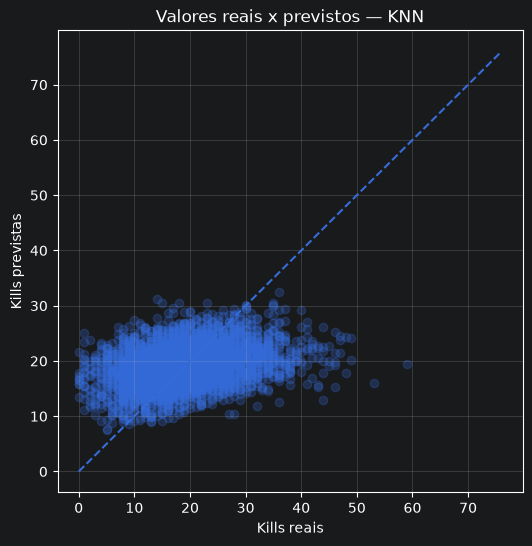

In [14]:
# VISUALIZAÇÃO DOS RESULTADOS

quantidade_amostra = min(5000, len(y_teste))
amostra = np.random.default_rng(42).choice(len(y_teste), size=quantidade_amostra, replace=False)

plt.figure(figsize=(6, 6))
plt.scatter(
    y_teste.iloc[amostra],
    previsoes_teste[amostra],
    alpha=0.25
)
limite = max(float(y_teste.max()), float(np.max(previsoes_teste)))
plt.plot([0, limite], [0, limite], linestyle="--")
plt.xlabel("Kills reais")
plt.ylabel("Kills previstas")
plt.title("Valores reais x previstos — KNN")
plt.grid(alpha=0.3)
plt.show()

In [15]:
# ANÁLISE DOS ERROS

analise_erros = pd.DataFrame({
    "real": y_teste.to_numpy(),
    "previsto": previsoes_teste
})
analise_erros["erro_absoluto"] = (analise_erros["real"] - analise_erros["previsto"]).abs()

analise_erros["faixa_kills"] = pd.cut(
    analise_erros["real"],
    bins=[-0.001, 5, 10, 15, 20, 30, np.inf],
    labels=["0–5", "6–10", "11–15", "16–20", "21–30", "31+"]
)

display(
    analise_erros.groupby("faixa_kills", observed=False)
    .agg(
        Quantidade=("real", "size"),
        MAE=("erro_absoluto", "mean"),
        Média_real=("real", "mean"),
        Média_prevista=("previsto", "mean")
    )
    .round(3)
)

,Quantidade,MAE,Média_real,Média_prevista
faixa_kills,,,,
0–5,657,13.576,3.160,16.735
6–10,2304,8.856,8.490,17.331
11–15,5391,5.172,13.243,18.197
16–20,7219,2.668,18.018,18.967
21–30,8615,4.949,24.427,19.907
31+,1730,14.443,35.526,21.086


In [16]:
# SALVAMENTO DOS RESULTADOS

# 1. Salva os resultados da busca tradicional (Grid Search).
salvar_resultados(busca, resumo)

# 2. Organiza os resultados finais dos três modelos.
tabela_teste = pd.DataFrame([
    {
        "conjunto": "teste",
        "modelo": "baseline_media",
        "k": None,
        "distancia": None,
        "partidas": len(teste),
        **baseline_teste
    },
    {
        "conjunto": "teste",
        "modelo": "knn_grid_search",
        "k": configuracao["k"],
        "distancia": configuracao["distancia"],
        "partidas": len(teste),
        **metricas_grid
    },
    {
        "conjunto": "teste",
        "modelo": "knn_pso",
        "k": configuracao_pso["k"],
        "distancia": configuracao_pso["distancia"],
        "partidas": len(teste),
        **metricas_pso
    },
]).astype({"k": "Int64"})

# 3. Salva a tabela.
salvar_tabela(tabela_teste, "knn_teste.csv")

display(tabela_teste)

print(
    "Arquivos salvos em results/metrics/: "
    "knn_busca.csv, knn_kills.csv, knn_teste.csv"
)

,conjunto,modelo,k,distancia,partidas,MAE,RMSE,R2
0,teste,baseline_media,<NA>,NaN,25916,5.412317,7.030461,0.128914
1,teste,knn_grid_search,15,manhattan,25916,5.559639,7.199385,0.086552
2,teste,knn_pso,15,manhattan,25916,5.559639,7.199385,0.086552


Arquivos salvos em results/metrics/: knn_busca.csv, knn_kills.csv, knn_teste.csv
